# College Physics 12th Edition

<img src="..//pics/cover.png" width=400> 



In [1]:
import setuptools

print("setuptools version:", setuptools.__version__)  # Should be < 70.0.0

import vpython as vp
from astropy import units as u
from astropy import constants as const
import sympy as sp
import numpy as np
from IPython.display import display, Math
import matplotlib.pyplot as plt
import sys
from pathlib import Path

print("All imports succeeded!")

setuptools version: 69.5.1


<IPython.core.display.Javascript object>

All imports succeeded!


In [2]:
# Add root folder to sys.path
sys.path.append(str(Path("..").resolve()))

# Import your helper function directly
from helper_functions import fmt_vec, oom


In [3]:
!python --version

Python 3.12.10


In [4]:
pwd


'c:\\Users\\crodr\\BK_tech\\Physics\\BK_College_Physics_Serway_12\\ch02'

# Topic 2 - Motion in One Dimension

## 2.1 Displacement, Velocity, and Acceleration

## 2.1.2 Velocity

### Average Velocity

The average velocity $\vec{v}$:

$$\vec{v} \equiv \frac{\Delta x}{\Delta t} = \frac{x_f - x_i}{t_f - t_i}$$

**SI unit**: meter per second (m/s)

### Instantaneous Velocity

The instantaneous velocity v:

$$v \equiv \lim_{\Delta t \to 0} \frac{\Delta x}{\Delta t}$$

**SI unit**: meter per second (m/s)



## 2.1.3 Speed

### Average Speed

$$\text{Average speed} \equiv \frac{\text{path length}}{\text{elapsed time}}$$

**SI unit**: meter per second (m/s)


### Example 2.1 The Tortoise and the Hare

page 34

**Goal** Apply the concept of average speed.


**Problem** A turtle and a rabbit engage in a footrace over a distance of 4.00 km. The rabbit runs 0.500 km and then stops for a 90.0 - min nap. Upon awakening, he remembers the race and runs twice as fast. Finishing the course in a total time of 1.75 h, the rabbit wins the race.

* **(a)** Calculate the average speed of the rabbit.  

* **(b)** What was his average speed before he stopped for a nap?

Assume no detours or doubling back.

**Strategy** Finding the overall average speed in part 

* **(a)** is just a matter of dividing the path length by the elapsed time. 

* **(b)** requires two equations and two unknowns, the latter turning out to be the two different average speeds: $v_1$ before the nap and $v_2$ after the nap. One equation is given in the statement of the problem ($v_2 = 2v_1$), whereas the other comes from the fact the rabbit ran for only 15 minutes because he napped for 90 minutes.



In [ ]:
# --- (a) ---
path_lengt_qty = 4 * u.km
elapsed_time_qty = 1.75 * u.h

av_speed_qty = path_lengt_qty / elapsed_time_qty

print(f"\n--- Part (a) ---")
print(f"Average Speed: av_speed_qty = {av_speed_qty:.3g}")


--- Part (a) ---
Average Speed: av_speed_qty = 2.29 km / h


In [ ]:
# --- (b) ---
# --- using SymPy ---

# 1. Define symbolic variables
t, d1, d2, v1, v2 = sp.symbols("t d_1 d_2 v_1 v_2", real=True, positive=True)

# 2. Define motion equation: d1/v1 + d2/v2 = t
eq_2 = sp.Eq(d1 / v1 + d2 / v2, t)

# 3. Substitute v2 = 2*v1, it runs twice as fast
eq_sub = eq_2.subs(v2, 2 * v1)

# 4. Solve for v1 (returns a list [expr])
v1_expr = sp.solve(eq_sub, v1)[0]

print(f"\n--- Part (b) ---")
display(Math(rf"v_1 = {sp.latex(v1_expr)}"))



--- Part (b) ---


<IPython.core.display.Math object>

In [ ]:
# ---Using AstroPy ---
d1_qty = 0.5 * u.km
d2_qty = 3.5 * u.km
t_qty = 0.25 * u.h

# --- Derive callables from SymPy ---
calc_v1 = sp.lambdify((d1, d2, t), v1_expr)

# --- 3. calculation ---
v1_qty = calc_v1(d1_qty, d2_qty, t_qty)

print(f"v1 =  {v1_qty:.1f}")

v1 =  9.0 km / h


#### Exercise 2.1

page 35

Estimate the average speed of the Apollo spacecraft in meters per second, given that the craft took five days to
reach the Moon from Earth. (The Moon is $3.8 \times 10^8 m $ from Earth.)

In [ ]:
t_qty = (5 * u.d).to(u.s)
d_qty = 3.8e8 * u.m

av_speed_qty = d_qty / t_qty
v_rounded_qty = round(av_speed_qty, -2)

print(f"Calculated average speed: {av_speed_qty:.0f}")
print(f"Rounded average speed: ~ {v_rounded_qty:.0f}")


Calculated average speed: 880 m / s
Rounded average speed: ~ 900 m / s


## 2.1.4 Acceleration

### Average Acceleration

$$\vec{a} \equiv \frac{\Delta v}{\Delta t} = \frac{v_f - v_i}{t_f - t_i}$$

**SI unit**: meter per second per second ($m/s^2$)


### Instantaneous Acceleration

The instantaneous acceleration a:

$$a \equiv \lim_{\Delta t \to 0} \frac{\Delta v}{\Delta t}$$

**SI unit**: meter per second per second ($m/s^2$)


# 2.3 One-Dimensional Motion with Constant Acceleration


$$a = \frac{v_f - v_i}{t_f - t_i}$$

$$a = \frac{v - v_0}{t}$$

$$v = v_0 + a t$$

$$\bar{v} = \frac{v_0 + v}{2}$$

$$\Delta x = \frac{1}{2}(v_0 + v) t$$

$$\Delta x = v_0 t +  \frac{1}{2} a t^2$$

$$v^2 = v_0^2 + 2 a \Delta x$$


### Example 2.4 The Bathurst 1000

**Goal** Apply the kinematic equations.

**Problem** A race car starting from rest accelerates at a constant rate of 5.00 m/s2. 

* **(a)** How much time elapses until its velocity reaches 17.5 m/s? 

* **(b)** How far does it travel during that time interval? 

 * **(c)** Calculate its average velocity during the time interval. 
 
 * **(d)** What is its velocity after it has traveled 45.0 m from the starting line?


**Strategy** We’ve read the problem, drawn the diagram in Figure 2.16, and chosen a coordinate
system (steps 1 and 2). We’re given $a = 5.00 m/s^2$ and $v0 = 0 $ (because the car
starts from rest), completing step 3. Steps 4–6 will be completed below for each part of the
problem.

<img src="..//pics/Fig_2_16.png" width=300> 

In [ ]:
# --- Part (a) ---
a_qty = 5.00 * (u.m / u.s**2)
v_qty = 17.5 * (u.m / u.s)
v0_qty = 0 * (u.m / u.s)

# from eq: v = v0 + at ==> t = (v - v0) / a
t_qty = (v_qty - v0_qty) / a_qty

print("\n--- Part (a) ---")
print(f"Car reaches velocity: {v_qty} at time: {t_qty:.2f}")


--- Part (a) ---
Car reaches velocity 17.5 m / s at time 3.50 s


In [ ]:
# --- Part (b) ---
# eq: delta_x = v0 t + (1/2) a t^2
Dx_qty = v0_qty * t_qty + (1 / 2) * a_qty * t_qty**2

print("\n--- Part (b) ---")
print(f"Car travels during time: {t_qty:.2f} the distance: {Dx_qty:.3g} ")



--- Part (b) ---
Car travels during time: 3.50 s the distance: 30.6 m 


In [18]:
# --- Part (c) ---
# eq: v_av = delta_x / delta_t
v_av_qty = Dx_qty / t_qty

print("\n--- Part (c) ---")
print(f"During time: {t_qty:.2f} interval the average velocity: {v_av_qty:.3g} ")


--- Part (c) ---
During time: 3.50 s interval the average velocity: 8.75 m / s 


In [19]:
# --- Part (d) ---
Dx_qty = 45.0 * u.m
# eq: v^2 = v0^2 + 2 a delta_x, (v0=0),  ==> v = (2 a delta_x)^(1/2)
vd_qty = np.sqrt(2 * a_qty * Dx_qty)

print("\n--- Part (d) ---")
print(f"After car has travel {Dx_qty} the velocity: {vd_qty:.3g} ")



--- Part (d) ---
After car has travel 45.0 m the velocity: 21.2 m / s 


#### Exercise 2.4 

Suppose the driver in this example slams on the brakes when the car is at $\Delta x = 45.0 m$, stopping the car in 4.00 s
with constant acceleration. Find 

* **(a)** the acceleration and 

* **(b)** the distance the car travels while braking.

In [ ]:
# --- Part (a) ---
t_qty = 4.00 * u.s

# from eq: v = v0 + a t
# when stops v=0, and v0 is the previous calculated velocity ==> a = -V0 / t
a_qty = -vd_qty / t_qty

print("\n--- Part (a) ---")
print(f"The acceleration: {a_qty:.2f} ")



--- Part (a) ---
The acceleration: -5.30 m / s2 


In [ ]:
# --- Part (b) ---
# from eq: x = v0 t + (1/2) a t^2
x_qty = vd_qty * t_qty + (1 / 2) * a_qty * t_qty**2

print("\n--- Part (b) ---")
print(f"The distance the car travels while braking: {x_qty:.3g} ")



--- Part (b) ---
The distance the car travels while braking: 42.4 m 


### Example 2.5 Gliding to a Stop

**Goal** Apply the kinematic equations.

**Problem** An ice skater glides along a straight line in the positive x -direction, steadily slowing from 5.00 m/s to a stop in 8.00 s.

* **(a)** Calculate the ice skater’s acceleration. 

* **(b**) How far did the skater glide while stopping? 

* **(c)** Find the skater’s speed after gliding a distance of 10.0 m.

**Strategy** We’ve read the problem and can draw a skater gliding in the positive x -direction (steps 1 and 2). From the problem
statement, we know the initial and final velocities are $ v0 = +5.00 m/s$ and $v = 0 m/s$, and that $t = 8.00 s$ (step 3). Steps 4–6 will be completed below for each part of the problem.

In [ ]:
v0_qty = 5.00 * (u.m / u.s)
v_qty = 0 * (u.m / u.s)
t_qty = 8.00 * u.s

# --- Part (a) ---
# from eq: V = V0 + a t ==> a = (v - v0) / t
a_qty = (v_qty - v0_qty) / t_qty


print("\n--- Part (a) ---")
print(f"ice skater's acceleration: {a_qty}")

# --- Part (b) ---
# from eq: Dx = (1/2)* (V0 + v) * t
Dx_qty = (1 / 2) * (v0_qty + v_qty) * t_qty


print("\n--- Part (b) ---")
print(f"the skater glide: {Dx_qty}")

# --- Part (c) ---
x_qty = 10.0 * u.m
# from eq: v^2 = v0^2 + 2 a x ==> v = (v0^2 + 2 a x)^(1/2)
v_10_qty = np.sqrt(v0_qty**2 + 2 * a_qty * x_qty)


print("\n--- Part (c) ---")
print(f"skater's speed at {x_qty} glide: {v_10_qty:.3g}")


--- Part (a) ---
ice skater's acceleration: -0.625 m / s2

--- Part (b) ---
the skater glide: 20.0 m

--- Part (c) ---
skater's speed at 10.0 m glide: 3.54 m / s


In [33]:
(v_qty - v0_qty) / t_qty

<Quantity -1.25 m / s2>

### Exercise 2.5 

For the skater in this example, 

* **(a)** find the time t when the velocity reaches half its initial value. 

* **(b)** Calculate the
displacement Dx at that time and compare to the 20.0-m stopping distance.

In [ ]:
# from eq: v^2 = v0^2 + 2 a x ==> x = (v^2 - v0^2) / 2a
# v = v0/2
x_qty = ((v0_qty / 2) ** 2 - v0_qty**2) / (2 * a_qty)

# from eq: x = (1/2)(v0 + v) t ==> t = 2 x / (v + v0)
t_qty = (2 * x_qty) / (v0_qty + (v0_qty / 2))

print("\n--- Part (a) ---")
print(f"time: {t_qty}")

print("\n--- Part (b) ---")
print(f"Displacement: {x_qty}")



--- Part (a) ---
time: 4.0 s

--- Part (b) ---
Displacement: 15.0 m


### Example 2.6 Car Chase

page 46

**Goal** Solve a problem involving two objects, one moving at constant
acceleration and the other at constant velocity.

**Problem** A car traveling at a constant speed of 24.0 m/s passes a
trooper hidden behind a billboard, as in Figure 2.17. One second
after the speeding car passes the billboard, the trooper sets off in
chase with a constant acceleration of 3.00 m/s2. 

* **(a)** How long does it take the trooper to overtake the speeding car? 

* **(b)** How fast is the trooper going at that time?

**Strategy** Solving this problem involves two simultaneous kinematics
equations of position: one for the trooper and the other for the
car. Choose t = 0 to correspond to the time the trooper takes up the
chase, when the car is at $x_{car} = 24.0 m$ because of its head start $(24.0 m/s \times 1.00 s)$. The trooper catches up with the car when their positions are the same. This suggests setting $x_{trooper} = x_{car}$ and solving for time, which can then be used to find the trooper’s speed in part (b).

<img src="..//pics/Fig_2_17.png" width=400> 




In [5]:
a, x, x0, v, v0, t = sp.symbols("a, x, x_0, v, v_0, t", real=True, positive=True)

x_car_expr = x0 + v0 * t
x_trooper_expr = sp.Rational(1, 2) * a * t**2
x_eq = sp.Eq(x_car_expr, x_trooper_expr)

t_expr = sp.solve(x_eq, t)[1]

t_expr


(v_0 + sqrt(2*a*x_0 + v_0**2))/a

In [ ]:
# --- Part (a) ---
t_calc = sp.lambdify((v0, a, x0), t_expr)

v0_qty = 24.0 * (u.m / u.s)
a_qty = 3.00 * (u.m / u.s**2)
x0_qty = 24.0 * u.m

t_qty = t_calc(v0_qty, a_qty, x0_qty)

print("\n--- Part (a) ---")
print(f"Trooper overtakes sppeding car at t = {t_qty:.3g}")


--- Part (a) ---
Trooper overtakes sppeding car at t = 16.9 s


In [8]:
# --- Part (b) ---
# from eq: v = a t
v_trooper_qty = a_qty * t_qty

print("\n--- Part (b) ---")
print(f"Trooper overtakes speeding car with velocity = {v_trooper_qty:.3g}")


--- Part (b) ---
Trooper overtakes speeding car with velocity = 50.8 m / s


#### Question 2.6 
The graphical solution corresponds to finding the intersection of what two types of curves in the tx - plane?

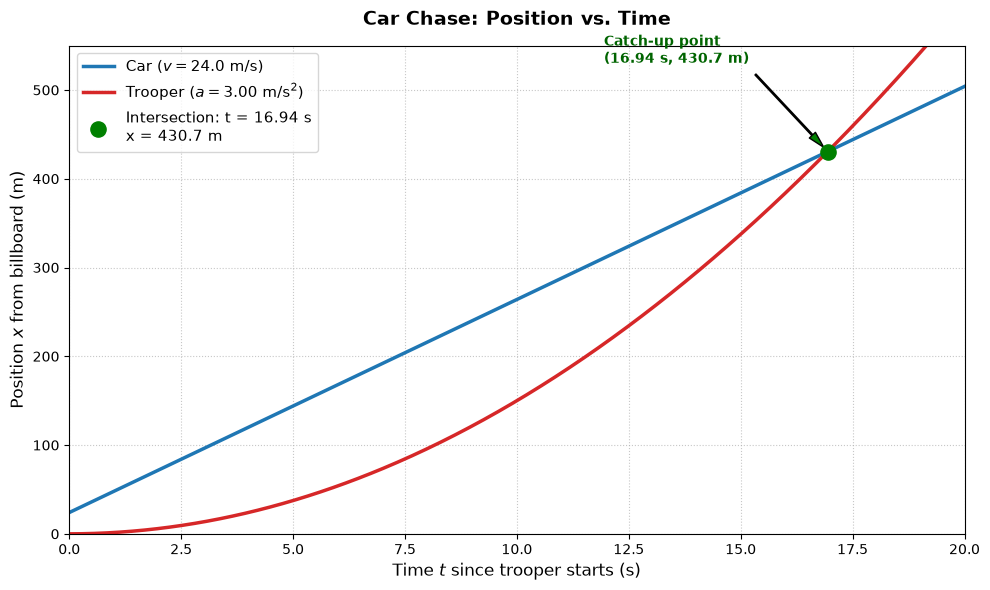

In [9]:
# Time array starting from t = 0 (the moment the trooper starts chasing)
t = np.linspace(0, 20, 500)

# Position equations (taking t = 0 when the trooper starts)
# Car has a 24.0 m head start and moves at a constant 24.0 m/s
x_car = 24.0 + 24.0 * t

# Trooper starts at x = 0 at t = 0 with a constant acceleration of 3.00 m/s^2
x_trooper = 0.5 * 3.00 * t**2

# Calculate the exact intersection point analytically:
# 1.5 * t^2 - 24.0 * t - 24.0 = 0  =>  t^2 - 16 * t - 16 = 0
t_intersect = 8 + np.sqrt(80)  # approximately 16.94 s
x_intersect = 24.0 + 24.0 * t_intersect  # approximately 430.67 m

# Create the plot
plt.figure(figsize=(10, 6))

# Plot trajectories
plt.plot(
    t,
    x_car,
    label="Car ($v = 24.0 \\text{ m/s}$)",
    color="#1f77b4",
    linewidth=2.5,
)
plt.plot(
    t,
    x_trooper,
    label="Trooper ($a = 3.00 \\text{ m/s}^2$)",
    color="#d62728",
    linewidth=2.5,
)

# Highlight the intersection point
plt.scatter(
    [t_intersect],
    [x_intersect],
    color="green",
    s=120,
    zorder=5,
    label=f"Intersection: t = {t_intersect:.2f} s\nx = {x_intersect:.1f} m",
)

# Annotate the intersection point on the graph
plt.annotate(
    f"Catch-up point\n({t_intersect:.2f} s, {x_intersect:.1f} m)",
    xy=(t_intersect, x_intersect),
    xytext=(t_intersect - 5, x_intersect + 100),
    arrowprops=dict(facecolor="green", shrink=0.05, width=1, headwidth=6),
    fontsize=10,
    fontweight="bold",
    color="darkgreen",
)

# Formatting the plot
plt.title("Car Chase: Position vs. Time", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Time $t$ since trooper starts (s)", fontsize=12)
plt.ylabel("Position $x$ from billboard (m)", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11, loc="upper left")
plt.xlim(0, 20)
plt.ylim(0, 550)

# Display the plot
plt.tight_layout()
plt.show()

### Exercise 2.6 

A motorist with an expired license tag is traveling at a constant 10.0 m/s down a street, and a police officer on a
motorcycle, taking another 5.00 s to react, gives chase at an acceleration of 2.00 m/s2. Find 
* **(a)** the time required to catch the car and 

* **(b)** the distance the officer travels while overtaking the motorist.

In [ ]:
# --- Part (a) ---
t_calc = sp.lambdify((v0, a, x0), t_expr)

v0_qty = 10.0 * (u.m / u.s)
a_qty = 2.00 * (u.m / u.s**2)
x0_qty = 50.0 * u.m  # 5 s x 10 m/s = 50 m, reaction time of the police officer

t_qty = t_calc(v0_qty, a_qty, x0_qty)

print("\n--- Part (a) ---")
print(f"Time required to catch the car t = {t_qty:.3g}")


--- Part (a) ---
Time required to catch the car t = 13.7 s


In [ ]:
# --- Part (b) ---
# from eq: x = (1/2) a t^2
x_trooper_qty = (1 / 2) * a_qty * t_qty**2

print("\n--- Part (b) ---")
print(
    f"The distance the officer travels while overtaking the motorist = {x_trooper_qty:.3g}"
)


--- Part (b) ---
The distance the officer travels while overtaking the motorist = 187 m


### Example 2.7 Runway Length

page 47

**Goal** Apply kinematics to horizontal motion with two phases.

**Problem** A typical jetliner lands at a speed of $1.60 \times 10^2 mi/h$
and decelerates at the rate of (10.0 mi/h)/s. If the plane travels at
a constant speed of $1.60 \times 10^2 mi/h$ for 1.00 s after landing before
applying the brakes, what is the total displacement of the aircraft
between touchdown on the runway and coming to rest?

**Strategy** See Figure 2.18. First, convert all quantities to SI units.
The problem must be solved in two parts, or phases, corresponding
to the initial coast after touchdown, followed by braking. Using the
kinematic equations, find the displacement during each part and
add the two displacements.

<img src="..//pics/Fig_2_18.png" width=400> 



In [ ]:
# --- Using AstroPy ---
# --- Convert units to SI ---
v0_qty = 1.60e2 * (u.imperial.mi / u.h)
v0_si_qty = v0_qty.to(u.m / u.s)
a_qty = -10.0 * ((u.imperial.mi / u.h) / u.s)
a_si_qty = a_qty.to(u.m / u.s**2)
t_coasting_qty = 1.00 * u.s

# --- calculating coasting displacement ---
# from eq: Dx = v0 t + (1/2) a t^2
# During coasting a=0 ==> Dx = v0 t
Dx_coasting_qty = v0_si_qty * t_coasting_qty

# --- calculating braking displacement ---
# from eq: v^2 = v0^2 + 2 a x ==> x = (v^2 - v0^2) / (2 a)
# In braking final v=0
Dx_braking_qty = (0 - v0_si_qty**2) / (2 * a_si_qty)

# --- calculating total displacement ---
Dx_total_qty = Dx_coasting_qty + Dx_braking_qty

# --- results ---
print(f"Convert velocity to SI: v0 = {v0_si_qty:.3g}")
print(f"Convert acceleration to SI: v0 = {a_si_qty:.3g}")
print(f"Coasting displacement: Dx_coasting = {Dx_coasting_qty:.3g}")
print(f"Braking displacement: Dx_coasting = {Dx_braking_qty:.3g}")
print(f"Total displacement: Dx_total = {Dx_total_qty:.3g}")

Convert velocity to SI: v0 = 71.5 m / s
Convert acceleration to SI: v0 = -4.47 m / s2
Coasting displacement: Dx_coasting = 71.5 m
Braking displacement: Dx_coasting = 572 m
Total displacement: Dx_total = 644 m


#### Exercise 2.7 
A jet lands at 80.0 m/s, and the pilot applies the brakes 2.00 s after landing. Find the acceleration needed to stop
the jet within $5.00 \times 10^2 m$ after touchdown.

In [ ]:
# --- Using AstroPy ---
v0_si_qty = 80.0 * (u.m / u.s)
t_coasting_qty = 2.00 * u.s
Dx_total_qty = 5.00e2 * u.m

# --- calculating coasting displacement ---
# from eq: Dx = v0 t + (1/2) a t^2
# During coasting a=0 ==> Dx = v0 t
Dx_coasting_qty = v0_si_qty * t_coasting_qty

# --- calculating braking displacement ---
# from eq: total_displacement = x_coasting + x_braking ==> x_braking = total_displacement - x_costing
Dx_braking_qty = Dx_total_qty - Dx_coasting_qty

# --- calculating braking acceleration ---
# from eq: v^2 = v0^2 + 2 a x ==> a = (v^2 - v0^2) / (2 x)
# In braking final v=0
a_braking_qty = (0 - v0_si_qty**2) / (2 * Dx_braking_qty)

# --- results ---
print(f"Coasting displacement: Dx_coasting = {Dx_coasting_qty:.3g}")
print(f"Braking displacement: Dx_coasting = {Dx_braking_qty:.3g}")
print(f"Acceleration to stop the jet: a_braking_qty = {a_braking_qty:.3g}")


Coasting displacement: Dx_coasting = 160 m
Braking displacement: Dx_coasting = 340 m
Acceleration to stop the jet: a_braking_qty = -9.41 m / s2
